# Análise de condições agrícolas e previsão de culturas

**Aluno:** Pedro Victor Pires  
**RM:** 575181  
**Fase:** 3  
**Capítulo:** 2  

## Objetivo
Analisar dados de solo e clima associados a culturas agrícolas, descrever padrões, comparar três culturas e desenvolver cinco modelos de classificação para recomendar a cultura mais compatível com as condições informadas.

## 1. Bibliotecas e configuração

As bibliotecas abaixo serão usadas para manipulação de dados, visualização e construção/avaliação dos modelos.

In [6]:
# Se necessário, instale as dependências no ambiente Jupyter:
# %pip install pandas numpy matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 2. Carregamento da base

A base deve conter as colunas `N`, `P`, `K`, `temperature`, `humidity`, `ph`, `rainfall` e `label`. O código também aceita `pH` com letras maiúsculas/minúsculas diferentes.

In [7]:
arquivo = Path("produtos_agricolas.csv")

if not arquivo.exists():
    raise FileNotFoundError(
        "Não encontrei 'produtos_agricolas.csv'. Coloque o arquivo na mesma pasta "
        "do notebook e execute novamente esta célula."
    )

df = pd.read_csv(arquivo)
df.columns = [c.strip() for c in df.columns]

# Padroniza a coluna de pH sem alterar as demais variáveis.
colunas_lower = {c.lower(): c for c in df.columns}
if "ph" in colunas_lower and colunas_lower["ph"] != "ph":
    df = df.rename(columns={colunas_lower["ph"]: "ph"})

colunas_esperadas = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall", "label"]
faltantes = [c for c in colunas_esperadas if c not in df.columns]
if faltantes:
    raise ValueError(f"Colunas ausentes na base: {faltantes}")

df = df[colunas_esperadas].copy()
display(df.head())
print(f"Dimensões da base: {df.shape[0]} linhas e {df.shape[1]} colunas.")

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.88,82.00,6.50,202.94,rice
1,85,58,41,21.77,80.32,7.04,226.66,rice
2,60,55,44,23.00,82.32,7.84,263.96,rice
3,74,35,40,26.49,80.16,6.98,242.86,rice
4,78,42,42,20.13,81.60,7.63,262.72,rice


Dimensões da base: 2200 linhas e 8 colunas.


## 3. Análise exploratória

Nesta etapa são verificados os tipos de dados, valores ausentes, registros duplicados, estatísticas gerais e distribuição das culturas.

In [8]:
print("Informações gerais:")
display(df.info())

print("\nTipos de dados:")
display(df.dtypes)

print("\nValores ausentes por coluna:")
display(df.isna().sum().to_frame("valores_ausentes"))

print("\nQuantidade de linhas duplicadas:", df.duplicated().sum())

print("\nEstatísticas descritivas:")
display(df.describe(include="all").T)

print("\nQuantidade de exemplos por cultura:")
display(df["label"].value_counts().to_frame("quantidade"))

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB


None


Tipos de dados:


N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label              str
dtype: object


Valores ausentes por coluna:


,valores_ausentes
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0



Quantidade de linhas duplicadas: 0

Estatísticas descritivas:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
N,"2,200.00",NaN,NaN,NaN,50.55,36.92,0.00,21.00,37.00,84.25,140.00
P,"2,200.00",NaN,NaN,NaN,53.36,32.99,5.00,28.00,51.00,68.00,145.00
K,"2,200.00",NaN,NaN,NaN,48.15,50.65,5.00,20.00,32.00,49.00,205.00
temperature,"2,200.00",NaN,NaN,NaN,25.62,5.06,8.83,22.77,25.60,28.56,43.68
humidity,"2,200.00",NaN,NaN,NaN,71.48,22.26,14.26,60.26,80.47,89.95,99.98
ph,"2,200.00",NaN,NaN,NaN,6.47,0.77,3.50,5.97,6.43,6.92,9.94
rainfall,"2,200.00",NaN,NaN,NaN,103.46,54.96,20.21,64.55,94.87,124.27,298.56
label,2200,22,rice,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Quantidade de exemplos por cultura:


,quantidade
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


### 3.1 Tratamento e validação inicial

Registros duplicados exatos são removidos. As variáveis preditoras são convertidas para valores numéricos; valores inválidos tornam-se ausentes e serão tratados dentro dos pipelines dos modelos. A coluna `label` é obrigatória.

In [9]:
df = df.drop_duplicates().copy()

features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
for coluna in features:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

df["label"] = df["label"].astype("string").str.strip()
df = df.dropna(subset=["label"])
df = df[df["label"] != ""]

print("Dimensões após remoção de duplicatas e rótulos vazios:", df.shape)
print("Valores ausentes nas variáveis numéricas:")
display(df[features].isna().sum().to_frame("ausentes"))
print("Culturas distintas:", df["label"].nunique())

Dimensões após remoção de duplicatas e rótulos vazios: (2200, 8)
Valores ausentes nas variáveis numéricas:


,ausentes
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0


Culturas distintas: 22


## 4. Análise descritiva e visualizações

Os gráficos abaixo permitem observar a distribuição das culturas, a variação das características do solo/clima, relações entre variáveis e diferenças entre grupos. Cada visualização é acompanhada por uma interpretação gerada a partir dos próprios dados.

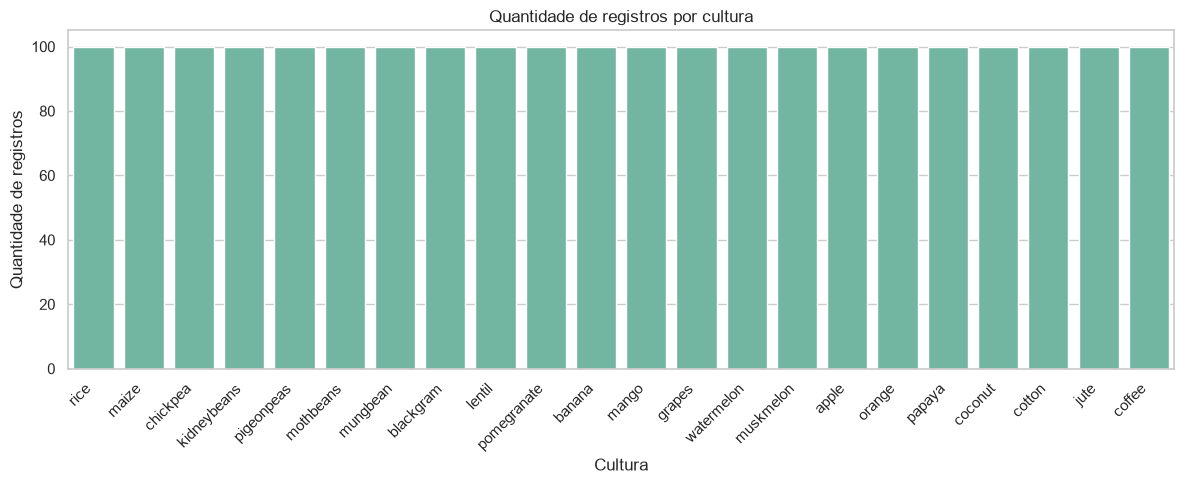

A base contém 22 culturas. A mais frequente é rice (100 registros) e a menos frequente é coffee (100 registros).


In [10]:
# Gráfico 1 — distribuição das culturas
plt.figure(figsize=(12, 5))
ordem = df["label"].value_counts().index
sns.countplot(data=df, x="label", order=ordem)
plt.title("Quantidade de registros por cultura")
plt.xlabel("Cultura")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

contagens = df["label"].value_counts()
print(f"A base contém {df['label'].nunique()} culturas. "
      f"A mais frequente é {contagens.index[0]} ({contagens.iloc[0]} registros) "
      f"e a menos frequente é {contagens.index[-1]} ({contagens.iloc[-1]} registros).")

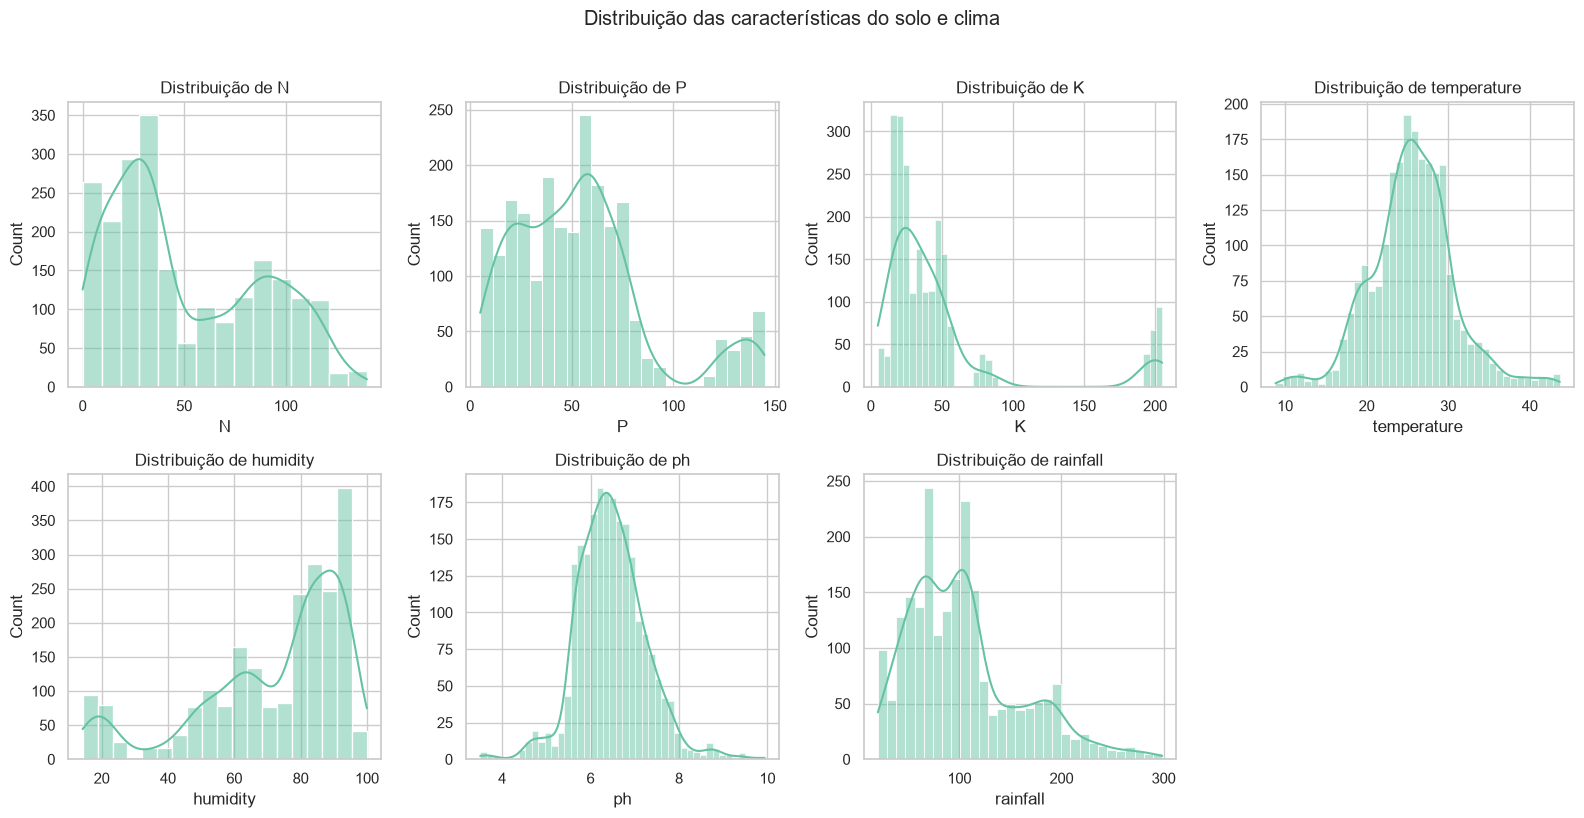

,assimetria
N,0.51
P,1.01
K,2.38
temperature,0.18
humidity,-1.09
ph,0.28
rainfall,0.97


In [11]:
# Gráfico 2 — distribuição das variáveis numéricas
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, coluna in zip(axes.flat, features):
    sns.histplot(df[coluna].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribuição de {coluna}")
    ax.set_xlabel(coluna)
axes.flat[-1].axis("off")
plt.suptitle("Distribuição das características do solo e clima", y=1.02)
plt.tight_layout()
plt.show()

display(df[features].skew().to_frame("assimetria"))

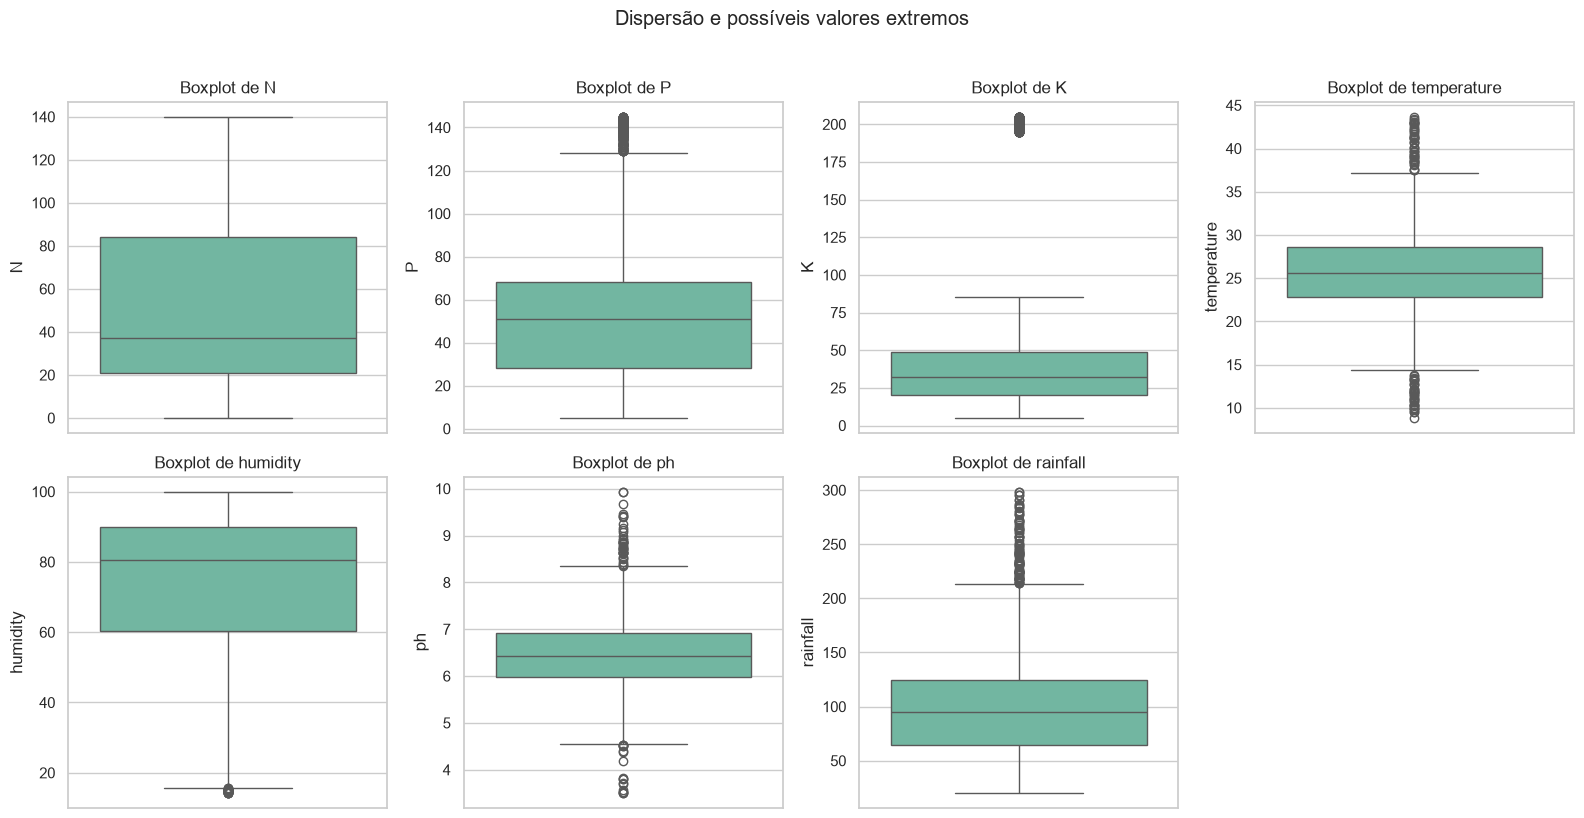

In [12]:
# Gráfico 3 — boxplots por variável
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, coluna in zip(axes.flat, features):
    sns.boxplot(y=df[coluna], ax=ax)
    ax.set_title(f"Boxplot de {coluna}")
axes.flat[-1].axis("off")
plt.suptitle("Dispersão e possíveis valores extremos", y=1.02)
plt.tight_layout()
plt.show()

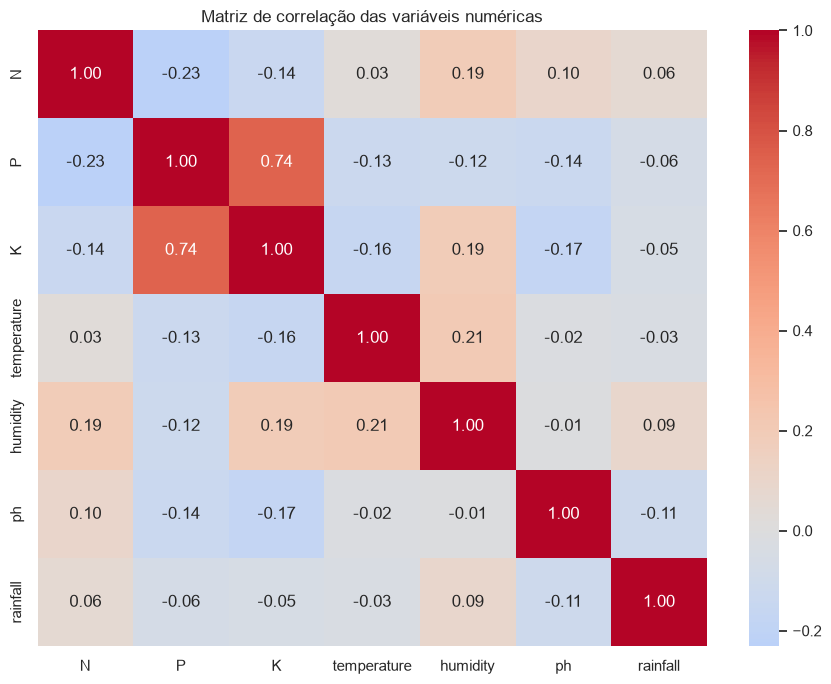

Maior correlação linear em valor absoluto: P e K (r = 0.74).


In [13]:
# Gráfico 4 — correlação entre variáveis numéricas
plt.figure(figsize=(9, 7))
corr = df[features].corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matriz de correlação das variáveis numéricas")
plt.tight_layout()
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
if len(pares):
    par = pares.abs().idxmax()
    print(f"Maior correlação linear em valor absoluto: {par[0]} e {par[1]} "
          f"(r = {corr.loc[par[0], par[1]]:.2f}).")

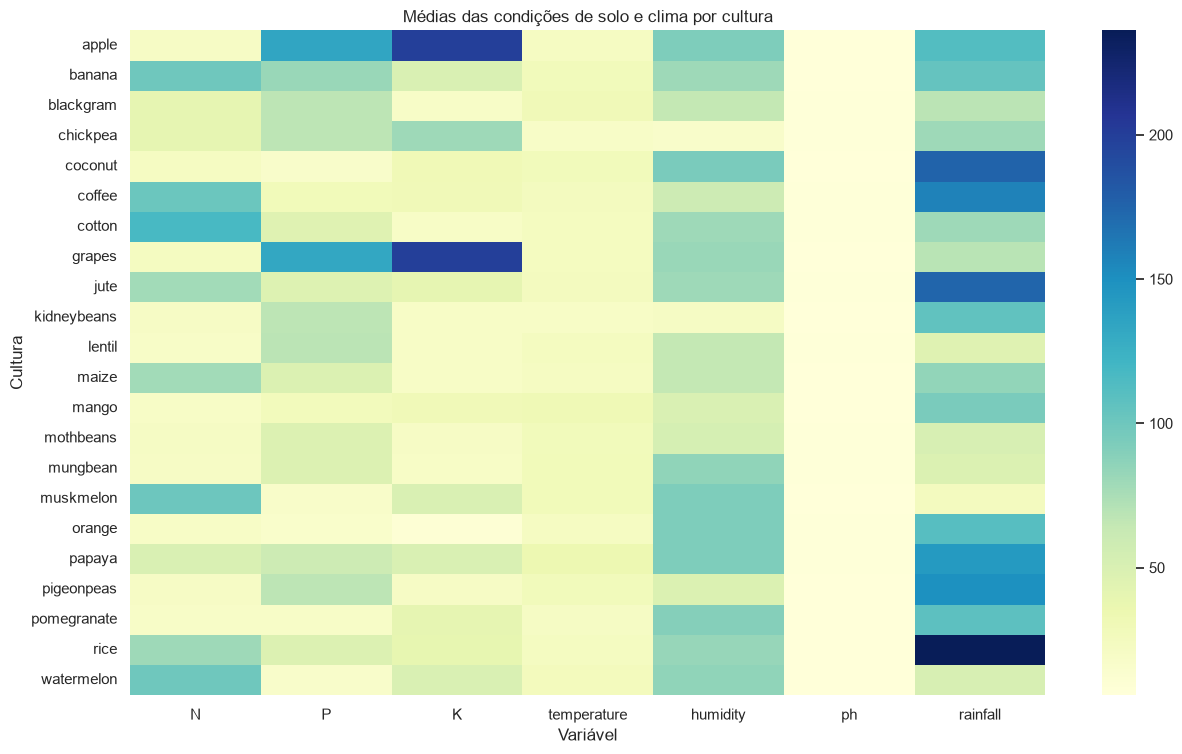

In [14]:
# Gráfico 5 — comparação de características por cultura (médias)
medias = df.groupby("label")[features].mean()
plt.figure(figsize=(13, max(6, len(medias) * 0.35)))
sns.heatmap(medias, cmap="YlGnBu", annot=False)
plt.title("Médias das condições de solo e clima por cultura")
plt.xlabel("Variável")
plt.ylabel("Cultura")
plt.tight_layout()
plt.show()

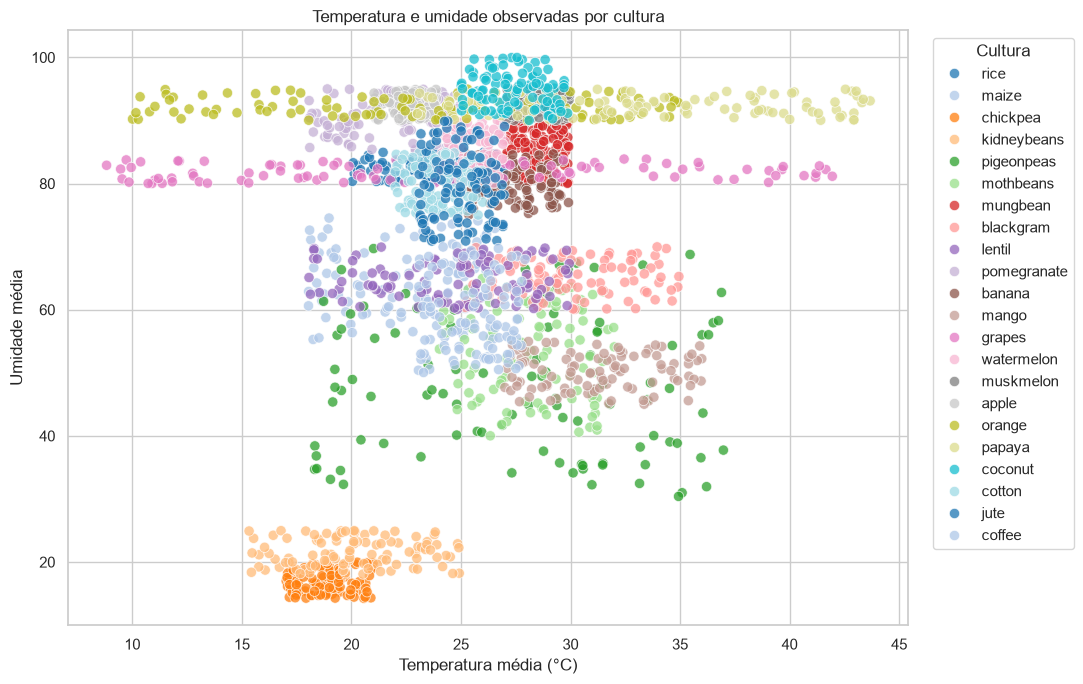

In [15]:
# Gráfico 6 — dispersão de temperatura e umidade por cultura
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df, x="temperature", y="humidity", hue="label",
    alpha=0.75, s=55, palette="tab20"
)
plt.title("Temperatura e umidade observadas por cultura")
plt.xlabel("Temperatura média (°C)")
plt.ylabel("Umidade média")
plt.legend(title="Cultura", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 4.1 Síntese descritiva automatizada

A tabela e o texto a seguir resumem amplitudes, médias e variabilidade. A interpretação deve considerar que associação entre variáveis não demonstra causalidade.

In [16]:
resumo = df[features].agg(["mean", "median", "std", "min", "max"]).T
display(resumo)

print("Síntese dos dados:")
for coluna in features:
    serie = df[coluna].dropna()
    print(f"- {coluna}: média {serie.mean():.2f}, mediana {serie.median():.2f}, "
          f"mínimo {serie.min():.2f} e máximo {serie.max():.2f}.")

,mean,median,std,min,max
N,50.55,37.00,36.92,0.00,140.00
P,53.36,51.00,32.99,5.00,145.00
K,48.15,32.00,50.65,5.00,205.00
temperature,25.62,25.60,5.06,8.83,43.68
humidity,71.48,80.47,22.26,14.26,99.98
ph,6.47,6.43,0.77,3.50,9.94
rainfall,103.46,94.87,54.96,20.21,298.56


Síntese dos dados:
- N: média 50.55, mediana 37.00, mínimo 0.00 e máximo 140.00.
- P: média 53.36, mediana 51.00, mínimo 5.00 e máximo 145.00.
- K: média 48.15, mediana 32.00, mínimo 5.00 e máximo 205.00.
- temperature: média 25.62, mediana 25.60, mínimo 8.83 e máximo 43.68.
- humidity: média 71.48, mediana 80.47, mínimo 14.26 e máximo 99.98.
- ph: média 6.47, mediana 6.43, mínimo 3.50 e máximo 9.94.
- rainfall: média 103.46, mediana 94.87, mínimo 20.21 e máximo 298.56.


## 5. Perfil de solo e clima de três culturas

Para tornar a escolha reproduzível, o notebook seleciona as três culturas com maior número de registros. Para cada uma, calcula mediana, média e intervalo interquartil (Q1–Q3) das sete variáveis. A mediana é usada como referência central por ser menos sensível a valores extremos.

**Atenção:** esse perfil representa as condições observadas na base, não uma recomendação agronômica universal. A produtividade também depende de variedade, manejo, época, região, pragas, irrigação e outras variáveis não presentes no dataset.

In [17]:
culturas_selecionadas = df["label"].value_counts().head(3).index.tolist()
print("Três culturas selecionadas:", culturas_selecionadas)

perfil = (
    df[df["label"].isin(culturas_selecionadas)]
    .groupby("label")[features]
    .agg(["count", "mean", "median", "std", lambda x: x.quantile(0.25),
          lambda x: x.quantile(0.75)])
)
perfil.columns = [
    f"{var}_{metrica if isinstance(metrica, str) else ('q1' if i == 4 else 'q3')}"
    for var, metrica in perfil.columns.to_flat_index()
    for i in [4 if metrica == "<lambda_0>" else 5 if metrica == "<lambda_1>" else 0]
]
display(perfil)

Três culturas selecionadas: ['rice', 'maize', 'chickpea']


,N_count,N_mean,N_median,N_std,N_<lambda_0>,N_<lambda_1>,P_count,P_mean,P_median,P_std,P_<lambda_0>,P_<lambda_1>,K_count,K_mean,K_median,K_std,K_<lambda_0>,K_<lambda_1>,temperature_count,temperature_mean,temperature_median,temperature_std,temperature_<lambda_0>,temperature_<lambda_1>,humidity_count,humidity_mean,humidity_median,humidity_std,humidity_<lambda_0>,humidity_<lambda_1>,ph_count,ph_mean,ph_median,ph_std,ph_<lambda_0>,ph_<lambda_1>,rainfall_count,rainfall_mean,rainfall_median,rainfall_std,rainfall_<lambda_0>,rainfall_<lambda_1>
label,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
chickpea,100,40.09,39.00,12.15,30.00,52.00,100,67.79,68.00,7.50,61.00,74.00,100,79.92,79.00,3.26,77.00,83.00,100,18.87,18.88,1.17,17.88,19.71,100,16.86,16.66,1.71,15.39,18.27,100,7.34,7.36,0.80,6.60,7.86,100,80.06,79.69,7.94,73.61,85.82
maize,100,77.76,76.00,11.95,67.75,87.00,100,48.44,48.50,8.01,42.75,56.00,100,19.79,20.00,2.94,17.00,22.00,100,22.39,22.84,2.68,19.82,24.90,100,65.09,65.30,5.45,60.58,69.43,100,6.25,6.26,0.41,5.85,6.60,100,84.77,83.47,15.55,70.38,99.88
rice,100,79.89,80.00,11.92,69.00,91.00,100,47.58,47.00,7.90,41.00,54.25,100,39.87,40.00,2.95,38.00,42.00,100,23.69,23.73,2.03,21.93,25.51,100,82.27,82.19,1.42,80.95,83.47,100,6.43,6.36,0.77,5.87,7.04,100,236.18,233.12,34.29,204.33,264.13


,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
chickpea,39.00,68.00,79.00,18.88,16.66,7.36,79.69
maize,76.00,48.50,20.00,22.84,65.30,6.26,83.47
rice,80.00,47.00,40.00,23.73,82.19,6.36,233.12


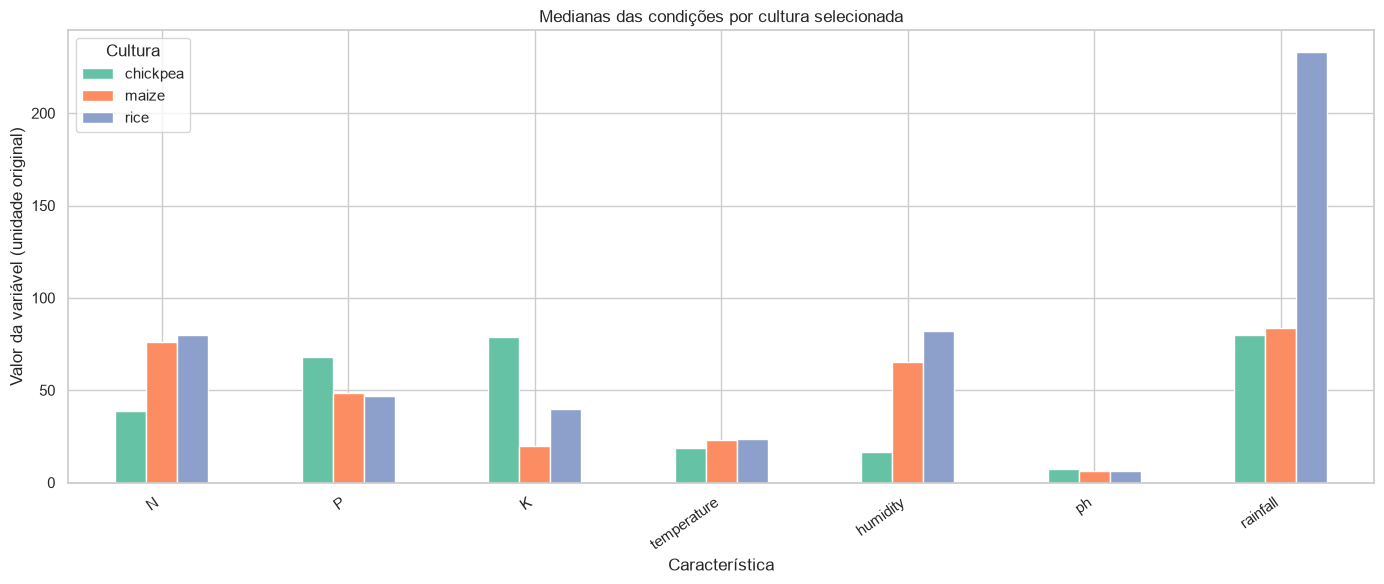


rice:
  N: mediana=80.00; faixa central (Q1–Q3)=69.00 a 91.00.
  P: mediana=47.00; faixa central (Q1–Q3)=41.00 a 54.25.
  K: mediana=40.00; faixa central (Q1–Q3)=38.00 a 42.00.
  temperature: mediana=23.73; faixa central (Q1–Q3)=21.93 a 25.51.
  humidity: mediana=82.19; faixa central (Q1–Q3)=80.95 a 83.47.
  ph: mediana=6.36; faixa central (Q1–Q3)=5.87 a 7.04.
  rainfall: mediana=233.12; faixa central (Q1–Q3)=204.33 a 264.13.

maize:
  N: mediana=76.00; faixa central (Q1–Q3)=67.75 a 87.00.
  P: mediana=48.50; faixa central (Q1–Q3)=42.75 a 56.00.
  K: mediana=20.00; faixa central (Q1–Q3)=17.00 a 22.00.
  temperature: mediana=22.84; faixa central (Q1–Q3)=19.82 a 24.90.
  humidity: mediana=65.30; faixa central (Q1–Q3)=60.58 a 69.43.
  ph: mediana=6.26; faixa central (Q1–Q3)=5.85 a 6.60.
  rainfall: mediana=83.47; faixa central (Q1–Q3)=70.38 a 99.88.

chickpea:
  N: mediana=39.00; faixa central (Q1–Q3)=30.00 a 52.00.
  P: mediana=68.00; faixa central (Q1–Q3)=61.00 a 74.00.
  K: mediana=79

In [18]:
# Comparação visual das medianas das três culturas selecionadas
medianas = df[df["label"].isin(culturas_selecionadas)].groupby("label")[features].median()
display(medianas)

ax = medianas.T.plot(kind="bar", figsize=(14, 6))
ax.set_title("Medianas das condições por cultura selecionada")
ax.set_ylabel("Valor da variável (unidade original)")
ax.set_xlabel("Característica")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Cultura")
plt.tight_layout()
plt.show()

for cultura in culturas_selecionadas:
    dados_cultura = df[df["label"] == cultura][features]
    print(f"\n{cultura}:")
    for coluna in features:
        q1, med, q3 = dados_cultura[coluna].quantile([0.25, 0.5, 0.75])
        print(f"  {coluna}: mediana={med:.2f}; faixa central (Q1–Q3)={q1:.2f} a {q3:.2f}.")

### 5.1 Interpretação do perfil

Use as medianas e os intervalos interquartis acima para comparar as três culturas. Valores maiores de umidade ou precipitação, por exemplo, indicam que os registros daquela cultura na base ocorreram em condições relativamente mais úmidas/chuvosas do que os das demais culturas selecionadas. Isso não significa, isoladamente, que aumentar essa variável causará maior produtividade.

O perfil de referência de cada cultura é o conjunto de medianas de `N`, `P`, `K`, temperatura, umidade, pH e precipitação. A faixa Q1–Q3 indica onde se concentra a metade central dos registros daquela cultura.

## 6. Preparação dos dados para Machine Learning

O problema é uma **classificação multiclasse**: as sete variáveis de solo/clima são as entradas e `label` é a classe a prever.

Boas práticas adotadas:
- Separação treino/teste estratificada para preservar a proporção das culturas;
- Imputação de valores ausentes dentro do pipeline;
- Padronização para algoritmos sensíveis à escala (KNN, SVM e regressão logística);
- Ajuste dos modelos somente no conjunto de treino;
- Avaliação final em conjunto de teste não utilizado no treinamento;
- Validação cruzada no treino para estimar estabilidade.

A padronização também é aplicada nos modelos de árvore por simplicidade de pipeline, embora árvores não dependam da escala.

In [19]:
X = df[features].copy()
y = df["label"].astype(str)

# Remove variáveis inteiramente vazias, que não poderiam ser imputadas.
colunas_validas = X.columns[X.notna().any()].tolist()
X = X[colunas_validas]
features_utilizadas = colunas_validas

contagem_classes = y.value_counts()
classes_validas = contagem_classes[contagem_classes >= 2].index
mascara = y.isin(classes_validas)
X = X.loc[mascara]
y = y.loc[mascara]

if y.nunique() < 2:
    raise ValueError("A base precisa conter pelo menos duas culturas com dois ou mais registros.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Variáveis utilizadas:", features_utilizadas)
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Número de culturas:", y.nunique())
display(y.value_counts().to_frame("total"))

Variáveis utilizadas: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Treino: (1760, 7) | Teste: (440, 7)
Número de culturas: 22


,total
label,
rice,100
maize,100
chickpea,100
kidneybeans,100
pigeonpeas,100
mothbeans,100
mungbean,100
blackgram,100
lentil,100


## 7. Treinamento de cinco modelos

Serão comparados cinco algoritmos diferentes: Árvore de Decisão, Random Forest, KNN, SVM e Regressão Logística. Os hiperparâmetros são configurações iniciais razoáveis, não uma busca exaustiva.

In [20]:
modelos = {
    "Árvore de Decisão": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("modelo", DecisionTreeClassifier(random_state=42, class_weight="balanced"))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("modelo", RandomForestClassifier(
            n_estimators=300, random_state=42, class_weight="balanced",
            n_jobs=-1
        ))
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("modelo", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("modelo", SVC(kernel="rbf", C=2.0, gamma="scale", class_weight="balanced"))
    ]),
    "Regressão Logística": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("modelo", LogisticRegression(
            max_iter=3000, class_weight="balanced", random_state=42
        ))
    ])
}

resultados = []
predicoes = {}
cv = StratifiedKFold(n_splits=min(5, int(y_train.value_counts().min())),
                     shuffle=True, random_state=42)

for nome, pipeline in modelos.items():
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    predicoes[nome] = pred

    resultados.append({
        "Modelo": nome,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, pred, average="macro", zero_division=0),
        "F1_weighted": f1_score(y_test, pred, average="weighted", zero_division=0),
        "F1_CV_media": cross_val_score(
            pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1
        ).mean()
    })

resultados_df = pd.DataFrame(resultados).sort_values("F1_macro", ascending=False)
display(resultados_df.round(4))

,Modelo,Accuracy,Precision_macro,Recall_macro,F1_macro,F1_weighted,F1_CV_media
1,Random Forest,0.99,0.99,0.99,0.99,0.99,0.99
3,SVM,0.99,0.99,0.99,0.99,0.99,0.98
0,Árvore de Decisão,0.98,0.98,0.98,0.98,0.98,0.99
2,KNN,0.98,0.98,0.98,0.98,0.98,0.96
4,Regressão Logística,0.97,0.97,0.97,0.97,0.97,0.97


## 8. Avaliação dos modelos

Acurácia mede a proporção total de previsões corretas. Precisão indica, em média, a proporção de previsões positivas corretas por classe; recall mede a capacidade de recuperar exemplos de cada classe; F1-score combina precisão e recall. A média macro dá o mesmo peso a cada cultura, enquanto a média ponderada considera a quantidade de exemplos por classe.

Para comparar as culturas sem deixar as classes mais frequentes dominarem a avaliação, o F1 macro será considerado junto com a acurácia e as demais métricas.

Modelo com maior F1 macro no conjunto de teste: Random Forest

Relatório de classificação:
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.95      0.97        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00 

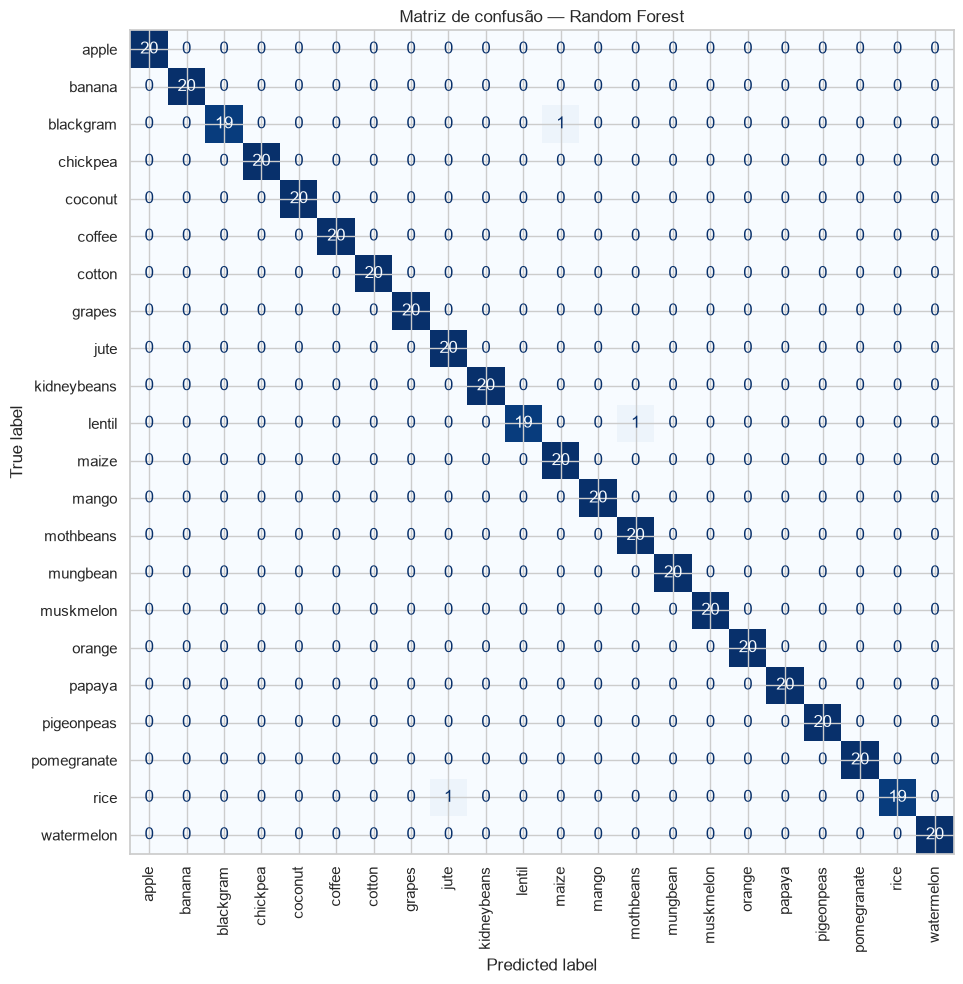

In [21]:
melhor_nome = resultados_df.iloc[0]["Modelo"]
melhor_modelo = modelos[melhor_nome]
melhor_pred = predicoes[melhor_nome]

print("Modelo com maior F1 macro no conjunto de teste:", melhor_nome)
print("\nRelatório de classificação:")
print(classification_report(y_test, melhor_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_test, melhor_pred, xticks_rotation=90, cmap="Blues",
    colorbar=False, ax=ax
)
ax.set_title(f"Matriz de confusão — {melhor_nome}")
plt.tight_layout()
plt.show()

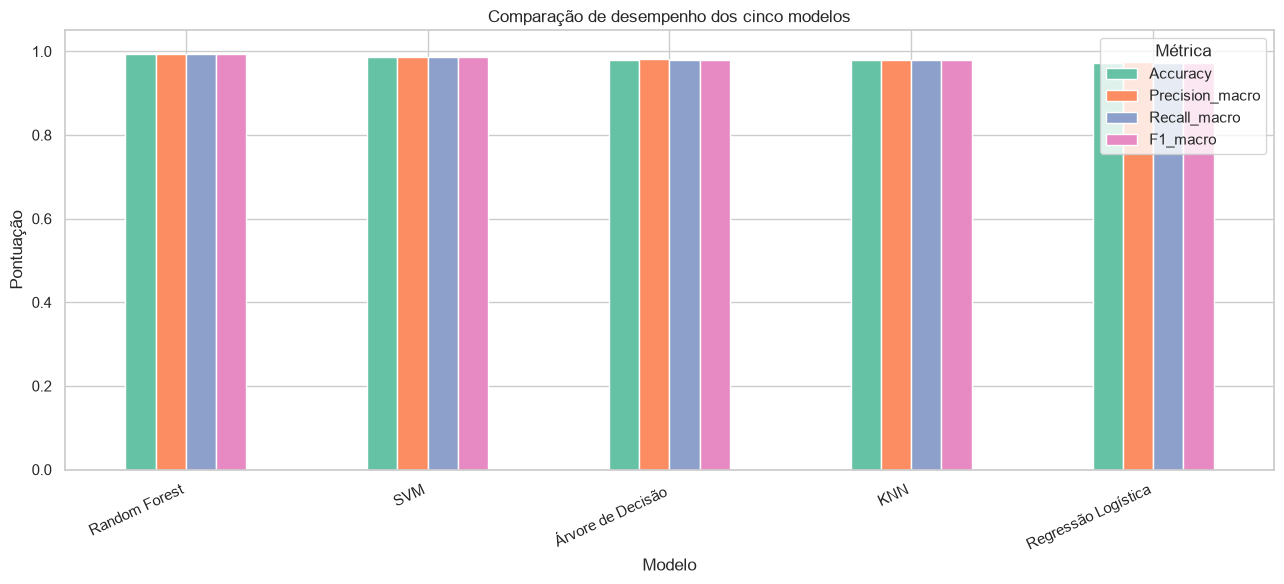

Melhor modelo pelo F1 macro: Random Forest.
A escolha final deve considerar também a matriz de confusão e o equilíbrio entre as classes.


In [22]:
# Comparação visual das métricas principais
metricas = ["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"]
comparacao = resultados_df.set_index("Modelo")[metricas]
ax = comparacao.plot(kind="bar", figsize=(13, 6))
ax.set_title("Comparação de desempenho dos cinco modelos")
ax.set_ylabel("Pontuação")
ax.set_ylim(0, 1.05)
ax.set_xlabel("Modelo")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()

print(f"Melhor modelo pelo F1 macro: {melhor_nome}.")
print("A escolha final deve considerar também a matriz de confusão e o equilíbrio entre as classes.")

## 9. Discussão dos resultados

A execução da tabela de métricas permite identificar o modelo com melhor desempenho no conjunto de teste. A validação cruzada fornece uma segunda referência de estabilidade no conjunto de treino.

**Como interpretar:**
- Se Accuracy e F1 macro forem próximos, o desempenho tende a estar relativamente equilibrado entre as classes.
- Se Accuracy for alta e F1 macro consideravelmente menor, algumas culturas podem estar sendo classificadas pior que outras.
- Na matriz de confusão, valores fora da diagonal representam confusões entre culturas.
- Uma diferença grande entre F1 da validação cruzada e F1 do teste pode indicar instabilidade ou sensibilidade à divisão dos dados.

Os resultados não devem ser interpretados como garantia de produtividade no campo. O modelo aprende padrões de associação presentes na base e recomenda a classe mais semelhante aos exemplos históricos.

## 10. Conclusão

Este trabalho organiza uma análise exploratória, descritiva e preditiva das condições de solo e clima associadas às culturas agrícolas. As estatísticas e visualizações permitem comparar a distribuição das variáveis e observar diferenças entre culturas. Os perfis baseados em mediana e intervalo interquartil resumem as condições registradas para três culturas selecionadas.

Na etapa preditiva, cinco algoritmos de classificação são treinados e avaliados com métricas complementares. A escolha do modelo deve considerar não apenas a acurácia, mas também o F1 macro, a validação cruzada e os erros apresentados na matriz de confusão.

**Pontos fortes:** uso de uma divisão estratificada entre treino e teste; pré-processamento dentro de pipelines; comparação de algoritmos distintos; avaliação com múltiplas métricas; análise visual e estatística das características.

**Limitações:** os dados podem não representar todas as regiões e safras; não há informações sobre variedade, manejo, custo, produtividade, pragas ou qualidade do solo além das variáveis disponíveis; o modelo identifica associações, não causalidade; não foi realizada uma otimização extensa de hiperparâmetros nem validação externa em outra base.

Portanto, os resultados devem ser utilizados como apoio exploratório à decisão, e não como substitutos de análise agronômica local.

## 11. Referências técnicas

- Documentação do pandas: https://pandas.pydata.org/docs/
- Documentação do Matplotlib: https://matplotlib.org/stable/
- Documentação do Seaborn: https://seaborn.pydata.org/
- Documentação do scikit-learn: https://scikit-learn.org/stable/

---

**Checklist antes da entrega**
1. Colocar `produtos_agricolas.csv` na mesma pasta deste notebook.
2. Executar todas as células em ordem (`Kernel > Restart & Run All`).
3. Conferir se os seis gráficos, tabelas e métricas foram gerados sem erros.
4. Revisar a discussão e a conclusão à luz dos resultados reais.
5. Salvar o notebook com as saídas das células e enviar o arquivo `.ipynb` na plataforma da FIAP.